In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import gaussian_kde
from numpy.linalg import LinAlgError

In [3]:
project_root = Path("..").resolve()

utils_path = project_root / "utils"
input_path = project_root / "data"
code_path = project_root / "code"

In [7]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import pandas as pd

project_root = Path.cwd().resolve()
while not (project_root / "requirements.txt").exists() and project_root != project_root.parent:
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

raw_dir = project_root / "data" / "exploratory"
processed_dir = project_root / "data" / "processed"

from utils.loaders import build_all, Dataset, REE_Y, ree_anomalies, apatite_qc_flags

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
datasets = build_all(raw_dir, processed_dir)   # ~15 s; rerun only when raw files change

georoc_apatite: 34491 analyses kept {'rows_in_file': 35353, 'rows_after_dropping_reference_footer': 34521, 'exact_duplicate_rows_dropped': 20, 'rows_without_any_detected_value_dropped': 10}
   unparsed cells: {('SiO2', 'SIO2(WT%)'): 132, ('Si', 'SIO2(WT%)->ppm'): 132, ('FeO', 'FEO(WT%)'): 2, ('Fe', 'FEO(WT%)->ppm'): 2, ('CaO', 'CAO(WT%)'): 132, ('Ca', 'CAO(WT%)->ppm'): 132, ('MnO', 'MNO(WT%)'): 219, ('Mn', 'MNO(WT%)->ppm'): 219, ('SrO', 'SRO(WT%)'): 4, ('Sr', 'SRO(WT%)->ppm'): 4, ('Na2O', 'NA2O(WT%)'): 132, ('Na', 'NA2O(WT%)->ppm'): 132, ('P2O5', 'P2O5(WT%)'): 132, ('P', 'P2O5(WT%)->ppm'): 132, ('F', 'F(WT%)'): 119, ('Cl', 'CL(WT%)'): 121, ('Rb', 'RB(PPM)'): 2, ('Sr', 'SR(PPM)'): 2, ('Nd', 'ND(PPM)'): 61, ('Sm', 'SM(PPM)'): 61, ('Pb', 'PB(PPM)'): 51, ('SR87_SR86', 'SR87_SR86'): 1, ('age_ma', 'AGE(MA)'): 239, ('age_pb206_u238_ma', 'AGE_PB206_U238(MA)'): 28}
osullivan_apatite: 1298 analyses kept {'rows_in_file': 1298}
ml2020_pyrite: 4369 analyses kept {'rows_in_file': 4371, 'rows_with_da

In [9]:
ap = Dataset.load(processed_dir, "apatite_all")
py = Dataset.load(processed_dir, "pyrite_all")

W = ap.wide(variables=REE_Y + ["Sr", "Th", "U", "Mn", "Ca", "F", "Cl"], with_meta=True)
W.groupby("dataset")[REE_Y].count().T     # coverage per dataset
ap.completeness(REE_Y + ["Sr", "Th", "U"])  # fraction detected per element

Ce    0.537959
Sr    0.459778
La    0.415742
Y     0.389785
Th    0.351086
U     0.338232
Nd    0.336975
Sm    0.319847
Pr    0.298080
Gd    0.285116
Eu    0.282349
Yb    0.280813
Dy    0.279192
Lu    0.273408
Er    0.270139
Ho    0.269273
Tb    0.262762
Tm    0.257174
dtype: float64

In [12]:
from utils.tables import apatite_table, FEATURES_FULL, FEATURES_SHARED
from utils.loaders import chondrite_normalise, ree_anomalies, REE_Y

X, labels, meta = apatite_table(processed_dir)   # one row per spot; all REE + Y required
print(X.shape, labels.shape, meta.shape)

(8650, 19) (8650, 9) (8650, 11)


In [13]:
labels.rock_class.value_counts()
pd.crosstab(labels.rock_class, labels.dataset)

dataset,GEOROC_apatite,OSullivan2019
rock_class,,
alkaline_silicate,606,46
bif_chert,69,0
carbonatite,573,61
felsic_plutonic,3179,188
felsic_volcanic,208,0
intermediate_plutonic,638,0
kimberlite_lamprophyre,121,0
mafic_interm_volcanic,459,0
mafic_plutonic,360,8


In [14]:
# one row per sample (median of its spots)
Xs, ls, ms = apatite_table(processed_dir, level="sample")

# features shared with O'Sullivan's phosphorites, for testing a GEOROC model on them
Xp, lp, mp = apatite_table(processed_dir, elements=FEATURES_SHARED, require=FEATURES_SHARED)

# keep everything, incomplete rows included
Xa, la, ma = apatite_table(processed_dir, require=[])

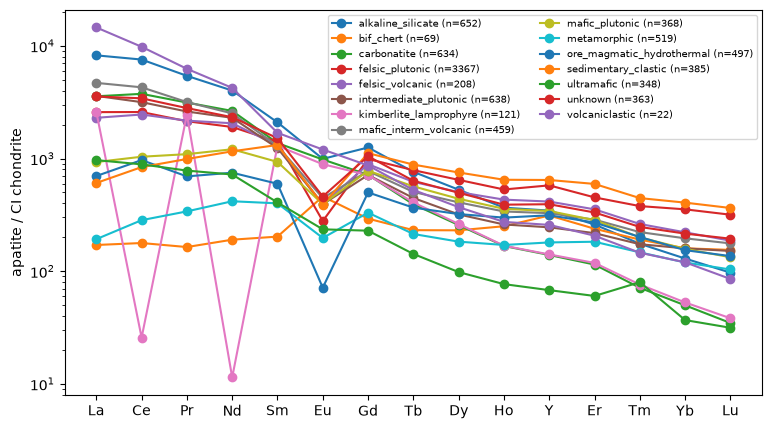

In [15]:
import matplotlib.pyplot as plt
N = chondrite_normalise(X)
med = N.groupby(labels.rock_class).median()
fig, ax = plt.subplots(figsize=(9, 5))
for cls, row in med.iterrows():
    ax.plot(row.index, row.values, marker="o", label=f"{cls} (n={(labels.rock_class == cls).sum()})")
ax.set_yscale("log"); ax.set_ylabel("apatite / CI chondrite"); ax.legend(fontsize=7, ncol=2)

In [16]:
A = ree_anomalies(Xp)              # Eu/Eu*, Ce/Ce*, Y/Ho, ΣREE, (La/Yb)N
A.join(lp.rock_class).groupby("rock_class").median().round(2)

,Eu_anom,Ce_anom,Y_Ho,sum_REE,La_Yb_N
rock_class,,,,,
alkaline_silicate,0.82,1.08,26.70,10060.21,61.48
bif_chert,1.78,0.95,35.79,484.43,1.21
carbonatite,0.96,1.09,24.46,5693.52,69.44
felsic_plutonic,0.28,1.08,29.94,4415.96,8.00
felsic_volcanic,0.46,1.12,26.77,4101.99,11.04
intermediate_plutonic,0.46,1.04,27.77,4850.01,23.43
kimberlite_lamprophyre,0.92,0.62,23.34,1412.05,45.42
mafic_interm_volcanic,0.48,1.06,26.10,5712.92,30.57
mafic_plutonic,0.64,1.02,27.03,2139.32,6.58
